In [1]:
import numpy as np
# Suppress warnings
import warnings
warnings.filterwarnings('ignore')
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.ticker import AutoMinorLocator
from scipy.ndimage import binary_opening, binary_closing, generate_binary_structure
from matplotlib.colors import ListedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
matplotlib.rcParams.update({'text.usetex': True})
plt.rcParams.update({
       "text.usetex": True,
       "font.family": "serif",
       "font.size": 16,
       "axes.labelsize": 16,
       "axes.titlesize": 16,
       "legend.fontsize": 14,
       "xtick.labelsize": 14,
       "ytick.labelsize": 14,
})
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}\usepackage{amssymb}'

### Quantum Dots' Parametrs

$ɛ = 1$ On-site mean local energy

$ɛ_L = ɛ + \frac{1}{2}δ$ On-site mean left energy

$ɛ_R = ɛ - \frac{1}{2}δ$ On-site mean right energy

$δ \in [0, 1.5]$ detuning

$g = 0.5 $ coupling strength

$Δ=\sqrt{δ^2+g^2}$


In [2]:
# Loading results of the Complete Positivity test
iscp_test_l0 = np.load('ph_avg_p.npz')['iscp_test_l0']

In [3]:
# Loading gain and loss rates (left and right) in the local basis
gamma_gain_l = np.load('rates_l.npz')['gamma_plus_2d']
gamma_loss_l = np.load('rates_l.npz')['gamma_minus_2d']
gamma_gain_r = np.load('rates_l.npz')['z_vals_2d']
gamma_loss_r = np.load('rates_l.npz')['t_vals_2d']

In [4]:
# Loading gain and loss rates (left and right) in the local basis
gammaL_p_dash = np.load('actual_rates_l.npz')['gammaL_p_dash']
gammaL_m_dash = np.load('actual_rates_l.npz')['gammaL_m_dash']
gammaR_p_dash = np.load('actual_rates_l.npz')['gammaR_p_dash']
gammaR_m_dash = np.load('actual_rates_l.npz')['gammaR_m_dash']

In [5]:
Lambda_dash_p_LR = np.load('koskos.npz')['Lambda_dash_p_LR']
Lambda_dash_m_LR = np.load('koskos.npz')['Lambda_dash_m_LR']

In [6]:
# Lamda RL PM matrix:
Lambda_dash_p_RL = Lambda_dash_p_LR.conjugate()
Lambda_dash_m_RL = Lambda_dash_m_LR.conjugate()

In [7]:
# Quantum Dots' Parametrs
eps = 1.0 # on-site mean local energy
delta = np.linspace(0.0,1.5,501)
g = 0.5 # coupling strength
Delta  = np.sqrt(delta**2 + g**2)
# Reservoirs' parameters
T = np.linspace(2e-2, 2e0, 501) #Temperature of the baths
muL = 0.7 # chemical potential of the left reservoir
muR = 0.0 # chemical potential of the right reservoir

### Fitted efficiencies vs. complete positivity (response to Referee)

The previous two-colour panel combined two **independent** conditions:

1. **Admissibility of the fitted rates**: $\eta^{\rm c}_k=\tilde\gamma^{\pm}_\alpha/\bar\gamma^{\pm}_\alpha\in[0,1]$ for all four site-basis rates ($k=1,\dots,4\leftrightarrow(L,-),(L,+),(R,-),(R,+)$) (the fitted jump rates must be non-negative and cannot exceed the actual rates, otherwise $\mathcal{L}^{\rm c}_{\rm imp}$ in Eq. (27) is not a valid dissipator);
2. **Complete positivity** of the no-click map $\mathcal{M}_0^{\rm c,imp}$ (Choi test, `iscp_test_l0`).

The cells below show them separately and then together. Note that the old cell only tested $\tilde\gamma<\bar\gamma$, not $\tilde\gamma\ge0$.

In [8]:
from scipy.ndimage import binary_closing
DENOISE = True           # remove isolated pixels from the boolean masks, as in your original Fig. 2 cell
DENOISE_SIZE = (2, 2)    # structuring element: np.ones(DENOISE_SIZE), same as before
CLOSE_HOLES = True       # also fill isolated 'holes' (opening alone only removes isolated True pixels); False = your original procedure
ETA_TOL = 0.0            # tolerance on the bounds: admissible if -ETA_TOL <= eta <= 1 + ETA_TOL
SAVE_AS = 'fig2_efficiencies'   # saves .pdf and .png in the working directory (None to skip)

rate_names = ['1 (L,-)', '2 (L,+)', '3 (R,-)', '4 (R,+)']   # k as in Sec. 4.2
fitted = [gamma_loss_l, gamma_gain_l, gamma_loss_r, gamma_gain_r]        # gamma_tilde (solutions of Eq. (61))
actual = [gammaL_m_dash, gammaL_p_dash, gammaR_m_dash, gammaR_p_dash]    # gamma_bar   (Lindblad rates, Eq. (5))

with np.errstate(divide='ignore', invalid='ignore'):
    eta = np.stack([f / a for f, a in zip(fitted, actual)])              # shape (4, n_delta, n_T)
eta[~np.isfinite(eta)] = np.nan

eta_min = np.nanmin(eta, axis=0)     # worst case for  eta >= 0
eta_max = np.nanmax(eta, axis=0)     # worst case for  eta <= 1

def clean(mask):
    # binary opening (as in your original cell) removes isolated True pixels;
    # optional closing fills isolated False pixels. Edge-padding avoids eroding the plot border.
    if not DENOISE:
        return mask
    pad = 2 * max(DENOISE_SIZE)
    st = np.ones(DENOISE_SIZE)
    m = binary_opening(np.pad(mask, pad, mode='edge'), st)
    if CLOSE_HOLES:
        m = binary_closing(m, st)
    return m[pad:-pad, pad:-pad]

cp_raw     = np.asarray(iscp_test_l0).astype(bool)
ok_min_raw = np.all(eta >= -ETA_TOL, axis=0)          # all eta^c_k >= 0      (NaN -> False)
ok_max_raw = np.all(eta <= 1 + ETA_TOL, axis=0)       # all eta^c_k <= 1      (NaN -> False)

cp     = clean(cp_raw)
ok_min = clean(ok_min_raw)
ok_max = clean(ok_max_raw)
admissible = ok_min & ok_max                          # eta^c_k in [0,1] for all k

# 0: CP & admissible | 1: not CP & admissible 
classes = np.where(cp & admissible, 0, 1)

# ---------------------------------------------------------------------------
# Numbers worth quoting in the response / caption
# ---------------------------------------------------------------------------
labels = ['CP & admissible', 'non-CP']
# compare the two criteria on the RAW masks, so that denoising does not enter the comparison
old_yes = cp_raw & np.all(np.stack([f < a for f, a in zip(fitted, actual)]), axis=0)   # old criterion (only gamma_tilde < gamma_bar)
new_yes = cp_raw & ok_min_raw & ok_max_raw

In [9]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

C_BLUE, C_GREEN, C_ORANGE, C_GREY = "#455D9B", "#61C461", "#E8A33D", "#9A9A9A"
extent = [delta[0]/eps, delta[-1]/eps, T[0]/eps, T[-1]/eps]
X, Y = delta/eps, T/eps

def style(ax, xlabel=False, ylabel=False):
    ax.tick_params(which='both', direction='in', top=True, bottom=True, left=True, right=True, labelsize=14)
    ax.xaxis.set_minor_locator(AutoMinorLocator()); ax.yaxis.set_minor_locator(AutoMinorLocator())
    if xlabel: ax.set_xlabel(r'$\delta/h$', fontsize=18)
    if ylabel: ax.set_ylabel(r'$T/h$', fontsize=18)

def cp_boundary(ax):
    ax.contour(X, Y, cp.T.astype(float), levels=[0.5], colors='black', linewidths=2.0, linestyles='-')

def diverging_norm(data, centre, half_default=0.5):
    lo = min(np.nanpercentile(data, 1),  centre - 0.05)
    hi = max(np.nanpercentile(data, 99), centre + 0.05)
    return TwoSlopeNorm(vcenter=centre, vmin=lo, vmax=hi)

In [10]:
good_rates_l = (
    (gamma_gain_l < gammaL_p_dash) &
    (gamma_loss_l < gammaL_m_dash) &
    (gamma_gain_r < gammaR_p_dash) &
    (gamma_loss_r < gammaR_m_dash) & 
    ((gammaL_p_dash - gamma_gain_l) * (gammaR_p_dash - gamma_gain_r) >= Lambda_dash_p_LR*Lambda_dash_p_RL) & 
    ((gammaL_m_dash - gamma_loss_l) * (gammaR_m_dash - gamma_loss_r) >= Lambda_dash_m_LR*Lambda_dash_m_RL)
)
mask_l = iscp_test_l0 & good_rates_l
iscp_for_contour_l = np.where(mask_l, 1.0, 0.0)

In [11]:
def iscp_kossakowski_local(gammaL_p_dash, gammaR_p_dash, gammaL_m_dash, gammaR_m_dash,
                           Lambda_dash_p_LR, Lambda_dash_m_LR, tol=0.0):
    """True where the local-basis Kossakowski matrix is positive semidefinite
       <=> e^{L t} is CPTP for all t >= 0.
       Blocks:  K^- = [[gL^-, Lam^-_LR], [Lam^-_RL, gR^-]]  in (c_L, c_R)
                K^+ = [[gL^+, Lam^+_RL], [Lam^+_LR, gR^+]]  in (c_L^dag, c_R^dag)
       Lam_RL = conj(Lam_LR), so |Lam_RL| = |Lam_LR|."""
    psd_plus  = ((gammaL_p_dash >= 0) & (gammaR_p_dash >= 0) &
                 (gammaL_p_dash*gammaR_p_dash - np.abs(Lambda_dash_p_LR)**2 >= -tol))
    psd_minus = ((gammaL_m_dash >= 0) & (gammaR_m_dash >= 0) &
                 (gammaL_m_dash*gammaR_m_dash - np.abs(Lambda_dash_m_LR)**2 >= -tol))
    return psd_plus & psd_minus

iscp_test_total_l = iscp_kossakowski_local(gammaL_p_dash, gammaR_p_dash, gammaL_m_dash, gammaR_m_dash,
                                         Lambda_dash_p_LR, Lambda_dash_m_LR, tol=0.0)

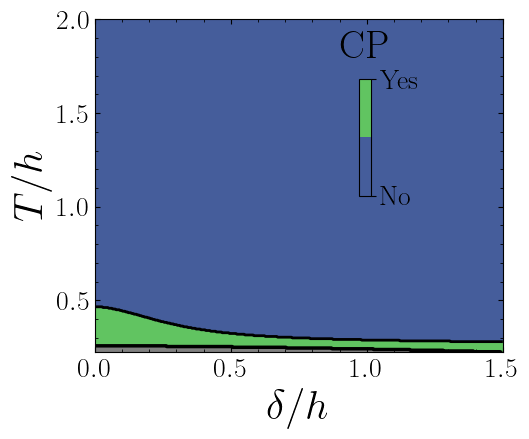

In [12]:
fig, axa = plt.subplots(1, 1, figsize=(8.5, 4.5))     # wider figure to leave room for the legend

clean = binary_closing(binary_opening(iscp_test_total_l, structure=np.ones((2,2))), structure=np.ones((1,2)))
region = clean.T > 0.5

classes_plot = np.ma.masked_where(
    ~region, classes.T
)

cmap = ListedColormap([C_BLUE, C_GREEN])
cmap.set_bad(alpha=1.0, color="grey")  # Set masked values to white

l1 = axa.imshow(classes_plot, extent=extent, origin='lower', aspect='auto', interpolation='none', cmap=cmap)

axa.contour(region.astype(float), levels=[0.5], extent=extent, origin='lower', colors='black', linewidths=2.5, linestyles='-')

cp_boundary(axa)

style(axa, xlabel=True, ylabel=True)
axa.tick_params(axis='x', labelsize=20)
axa.tick_params(axis='y', labelsize=20)
axa.xaxis.label.set_size(30)
axa.yaxis.label.set_size(30)

# rows of `region` are the T index (clean.T has shape (nT, n_delta))
rows = np.where(region.any(axis=1))[0]                 # T-rows that contain at least one True pixel
dy   = (extent[3] - extent[2]) / region.shape[0]       # height of one pixel in data units
ymin = extent[2] + rows.min() * dy                     # lower edge of the first row with region == True
axa.set_ylim(ymin, extent[3])

axi = inset_axes(axa, width="5%", height="50%", loc='upper right',
                 bbox_to_anchor=(0.15, 0.15, 0.55, 0.7),
                 bbox_transform=axa.transAxes, borderpad=0.5)
cbar1 = fig.colorbar(l1, cax=axi)
cbar1.set_ticks([0, 1], labels=["No", "Yes"])
cbar1.ax.set_title(r'$\mathrm{CP}$', pad=15, fontsize=28)
cbar1.ax.tick_params(labelsize=20)

fig.subplots_adjust(left=0.12, right=0.60, bottom=0.16, top=0.90)   
#fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/GitHub_V2/local_phase_diagram_all_v5.pdf', format='pdf', bbox_inches='tight')